# 📊 Análise Profunda e Cruzamentos Estratégicos: Municípios Brasileiros
### Base Oficial Consolidada: `traducao_municipios_consolidado.xlsx` (5.571 Municípios)
**Identidade Visual:** Cores oficiais da marca do Governo Federal (Azul `#1351B4`, Verde `#009B3A`, Vermelho `#D32727` e Amarelo `#FFCC00`).



In [11]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# Configuração de Estilo Visual Oficial (Cores Sólidas da Marca Brasil)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#D0D0D0'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.color'] = '#EAEAEA'
plt.rcParams['grid.linestyle'] = '--'

# Paleta Oficial Sólida (Sem degradê)
AZUL_GOV = '#1351B4'     # Azul institucional Brasil
VERDE_GOV = '#009B3A'    # Verde Brasil
VERMELHO_GOV = '#D32727' # Vermelho institucional
AMARELO_GOV = '#FFCC00'  # Amarelo ouro
PRETO_GOV = '#1D1D1B'    # Grafite escuro

OUTPUT_DIR = 'graficos_municipios'
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 1. Carregamento das abas oficiais
f_excel = 'traducao_municipios_consolidado.xlsx'
print("📂 Carregando base consolidada dos 5.571 municípios...")
df_prev = pd.read_excel(f_excel, sheet_name='Previdencia_Economia')
df_trab = pd.read_excel(f_excel, sheet_name='Trabalho_e_Renda')
df_educ = pd.read_excel(f_excel, sheet_name='Educacao_Escolas')
df_saude = pd.read_excel(f_excel, sheet_name='Saude_Medicamentos')

# 2. Merge limpo por cod_ibge7
df = df_prev[['cod_ibge7', 'municipio', 'uf', 'populacao_2025', 'valor_liquido_rgps_ano_brl', 
              'pib_municipal_precos_correntes_brl', 'aposentadorias_sobre_pib_pct', 
              'perda_hipotetica_por_habitante_brl', 'perda_hipotetica_anual_brl', 
              'aposentadorias_rgps_dezembro']].copy()

df = df.merge(df_trab[['cod_ibge7', 'trabalhadores_clt_ativos', 'total_mei_ativos', 
                       'familias_bolsa_familia', 'valor_mensal_bolsa_familia_rs', 
                       'beneficiarios_bpc_loas', 'valor_mensal_bpc_rs']], on='cod_ibge7')

df = df.merge(df_educ[['cod_ibge7', 'regiao', 'qtd_alunos_rede_publica', 'qtd_beneficiarios_pe_de_meia', 
                       'vl_pago_pe_de_meia', 'vl_fundeb_rede_municipal', 
                       'vl_fundeb_uniao_rede_municipal', 'pct_uniao_rede_municipal']], on='cod_ibge7')

df = df.merge(df_saude[['cod_ibge7', 'fp_total', 'bolso_anual_mediano_rs', 
                        'quimioterapia_pacientes', 'radioterapia_pacientes', 
                        'alto_custo_pacientes']], on='cod_ibge7')

# 3. Cálculos de Renda Social e Seguridade
df['bolsa_familia_ano'] = df['valor_mensal_bolsa_familia_rs'] * 12
df['bpc_ano'] = df['valor_mensal_bpc_rs'] * 12
df['renda_social_prev_total'] = df['valor_liquido_rgps_ano_brl'] + df['bolsa_familia_ano'] + df['bpc_ano']
df['pct_renda_social_pib'] = (df['renda_social_prev_total'] / df['pib_municipal_precos_correntes_brl']) * 100

# 4. Faixas de porte populacional
bins = [0, 10000, 20000, 50000, 100000, 500000, 20000000]
labels = ['Até 10 mil hab.', '10k a 20k hab.', '20k a 50k hab.', '50k a 100k hab.', '100k a 500k hab.', 'Acima de 500k hab.']
df['porte_pop'] = pd.cut(df['populacao_2025'], bins=bins, labels=labels)

print(f"✅ Base carregada: {len(df):,} municípios prontos para análise!")


📂 Carregando base consolidada dos 5.571 municípios...
✅ Base carregada: 5,571 municípios prontos para análise!


## 1. O Brasil da Seguridade Social: Top 15 Estados Mais Dependentes (% do PIB)
Soma de Aposentadorias RGPS + Bolsa Família + BPC/LOAS em relação ao PIB total dos municípios.
*Faixas de cores sólidas oficiais: Vermelho (>=20%), Amarelo (15% a 19,9%) e Azul (<15%). Maior número no topo e média nacional acima do gráfico.*


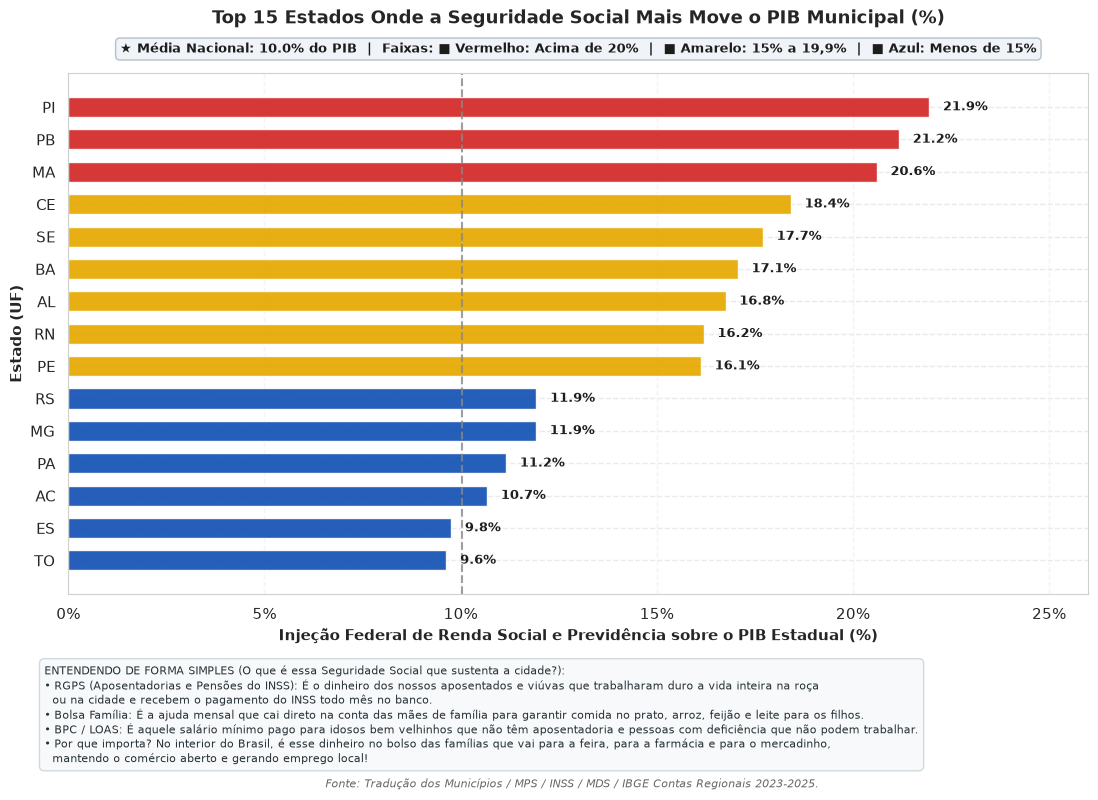

In [12]:
est_dep = df.groupby('uf').agg({
    'renda_social_prev_total': 'sum',
    'pib_municipal_precos_correntes_brl': 'sum'
}).reset_index()
est_dep['pct_pib'] = (est_dep['renda_social_prev_total'] / est_dep['pib_municipal_precos_correntes_brl']) * 100

# Top 15 ordenados do MAIOR para o MENOR (o maior ficará no topo do gráfico)
est_dep = est_dep.sort_values('pct_pib', ascending=False).head(15).reset_index(drop=True)

# Cores oficiais sólidas por faixa solicitada pelo usuário:
# >=20% Vermelho Oficial | 15% a 19.99% Amarelo Ouro | <15% Azul Institucional
AMARELO_OURO = '#E6A800'  # Amarelo contrastado para leitura perfeita em fundo branco
cores = []
for p in est_dep['pct_pib']:
    if p >= 20.0:
        cores.append(VERMELHO_GOV)
    elif p >= 15.0:
        cores.append(AMARELO_OURO)
    else:
        cores.append(AZUL_GOV)

fig, ax = plt.subplots(figsize=(12, 8.4))

bars = ax.barh(est_dep['uf'], est_dep['pct_pib'], color=cores, height=0.62, alpha=0.92)

# O maior número sempre em cima
ax.invert_yaxis()

ax.set_title('Top 15 Estados Onde a Seguridade Social Mais Move o PIB Municipal (%)', fontsize=13, fontweight='bold', pad=36)

# Comentário da média nacional e legenda das faixas posicionado ACIMA do gráfico
media_br = (df['renda_social_prev_total'].sum() / df['pib_municipal_precos_correntes_brl'].sum()) * 100
header_text = (
    f'★ Média Nacional: {media_br:.1f}% do PIB  |  '
    'Faixas: ■ Vermelho: Acima de 20%  |  ■ Amarelo: 15% a 19,9%  |  ■ Azul: Menos de 15%'
)
ax.text(0.5, 1.04, header_text, transform=ax.transAxes, ha='center', fontsize=9.2, fontweight='bold',
        color='#1D1D1B', bbox=dict(boxstyle='round,pad=0.35', facecolor='#F0F4F8', edgecolor='#B0BEC5', alpha=0.95))

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.35, bar.get_y() + bar.get_height()/2, f"{w:.1f}%", 
            ha='left', va='center', fontsize=9, fontweight='bold', color='#1D1D1B')

ax.set_xlim(0, 26)
ax.xaxis.set_major_formatter(ticker.FormatStrFormatter('%.0f%%'))
ax.set_xlabel('Injeção Federal de Renda Social e Previdência sobre o PIB Estadual (%)', fontsize=10.5, fontweight='bold')
ax.set_ylabel('Estado (UF)', fontsize=10.5, fontweight='bold')
ax.grid(axis='x', alpha=0.5)

# Linha da média nacional
ax.axvline(media_br, color='#888888', linestyle='--', linewidth=1.5, alpha=0.8)

# Comentário explicativo simples e acolhedor (para a mãe de 55 anos)
comentario_didatico = (
    "ENTENDENDO DE FORMA SIMPLES (O que é essa Seguridade Social que sustenta a cidade?):\n"
    "• RGPS (Aposentadorias e Pensões do INSS): É o dinheiro dos nossos aposentados e viúvas que trabalharam duro a vida inteira na roça\n"
    "  ou na cidade e recebem o pagamento do INSS todo mês no banco.\n"
    "• Bolsa Família: É a ajuda mensal que cai direto na conta das mães de família para garantir comida no prato, arroz, feijão e leite para os filhos.\n"
    "• BPC / LOAS: É aquele salário mínimo pago para idosos bem velhinhos que não têm aposentadoria e pessoas com deficiência que não podem trabalhar.\n"
    "• Por que importa? No interior do Brasil, é esse dinheiro no bolso das famílias que vai para a feira, para a farmácia e para o mercadinho,\n"
    "  mantendo o comércio aberto e gerando emprego local!"
)
fig.text(0.06, 0.04, comentario_didatico, fontsize=7.8, color='#263238', linespacing=1.35,
         bbox=dict(boxstyle='round,pad=0.45', facecolor='#F8F9FA', edgecolor='#CFD8DC', alpha=0.95))

fig.text(0.5, 0.01, 'Fonte: Tradução dos Municípios / MPS / INSS / MDS / IBGE Contas Regionais 2023-2025.', 
         ha='center', fontsize=8, style='italic', color='#666666')

plt.subplots_adjust(left=0.08, right=0.93, top=0.86, bottom=0.24)
plt.savefig(os.path.join(OUTPUT_DIR, 'grafico_1_dependencia_pib_estados.png'), dpi=300)
plt.show()


## 2. Pequenas Cidades vs. Metrópoles: O Peso da Seguridade Social por Porte
Quanto menor a cidade, maior é a dependência do comércio local em relação às aposentadorias e benefícios federais.
*Cores sólidas da marca do Governo Federal: Azul Institucional e Verde Brasil (sem degradê).*


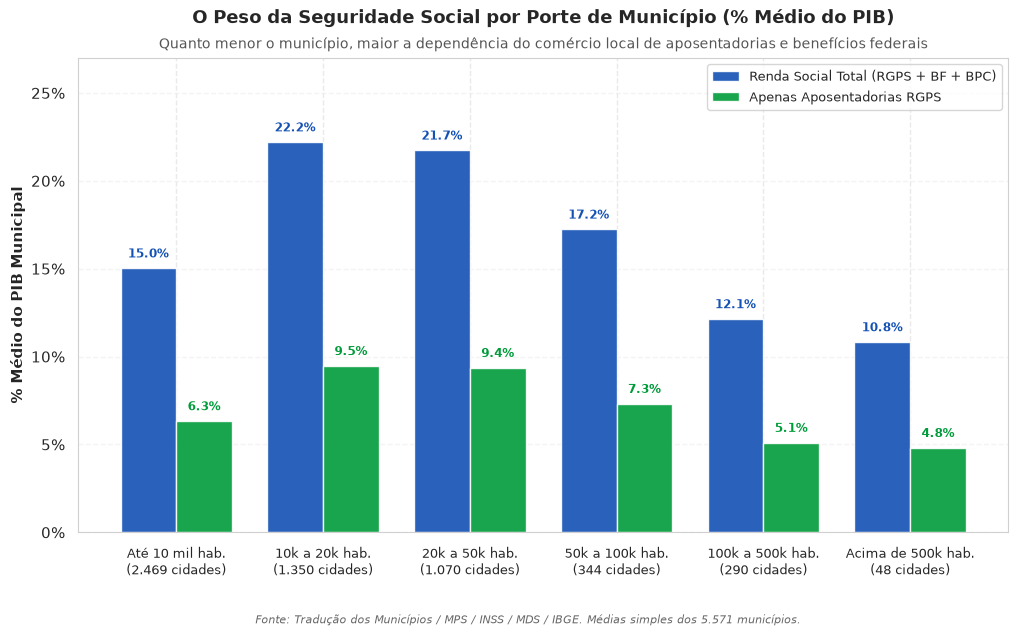

In [13]:
porte_stats = df.groupby('porte_pop', observed=False).agg({
    'cod_ibge7': 'count',
    'pct_renda_social_pib': 'mean',
    'aposentadorias_sobre_pib_pct': 'mean'
}).reset_index()

fig, ax = plt.subplots(figsize=(12, 6.5))
x = np.arange(len(porte_stats))
width = 0.38

# Cores sólidas oficiais: Azul e Verde
b1 = ax.bar(x - width/2, porte_stats['pct_renda_social_pib'], width, label='Renda Social Total (RGPS + BF + BPC)', color=AZUL_GOV, alpha=0.9)
b2 = ax.bar(x + width/2, porte_stats['aposentadorias_sobre_pib_pct'], width, label='Apenas Aposentadorias RGPS', color=VERDE_GOV, alpha=0.9)

ax.set_title('O Peso da Seguridade Social por Porte de Município (% Médio do PIB)', fontsize=13, fontweight='bold', pad=25)
ax.text(0.5, 1.02, 'Quanto menor o município, maior a dependência do comércio local de aposentadorias e benefícios federais', 
        transform=ax.transAxes, ha='center', fontsize=9.8, color='#555555')

for bar in b1:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.45, f"{h:.1f}%", ha='center', va='bottom', fontsize=8.8, fontweight='bold', color=AZUL_GOV)

for bar in b2:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.45, f"{h:.1f}%", ha='center', va='bottom', fontsize=8.8, fontweight='bold', color=VERDE_GOV)

ax.set_xticks(x)
ax.set_xticklabels([f"{p}\n({qtd:,} cidades)".replace(',', '.') for p, qtd in zip(porte_stats['porte_pop'], porte_stats['cod_ibge7'])], fontsize=9)
ax.set_ylabel('% Médio do PIB Municipal', fontsize=10.5, fontweight='bold')
ax.set_ylim(0, 27)
ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.0f%%'))
ax.legend(loc='upper right', frameon=True, fontsize=9.5)
ax.grid(axis='y', alpha=0.5)

fig.text(0.5, 0.01, 'Fonte: Tradução dos Municípios / MPS / INSS / MDS / IBGE. Médias simples dos 5.571 municípios.', 
         ha='center', fontsize=8, style='italic', color='#666666')
plt.subplots_adjust(top=0.88, bottom=0.15)
plt.savefig(os.path.join(OUTPUT_DIR, 'grafico_2_peso_seguridade_porte_cidades.png'), dpi=300)
plt.show()


## 3. Educação Básica: Quanto o Município Depende do FUNDEB da União (%)
No Nordeste, **40,5%** de todo o orçamento da rede municipal vem da complementação da União (R$ 33,7 bilhões). No Norte, **36,7%** (R$ 9,8 bilhões).
*Rótulos reposicionados com separação total entre valores absolutos (R$ Bi) e percentuais (% da rede), eliminando qualquer sobreposição.*


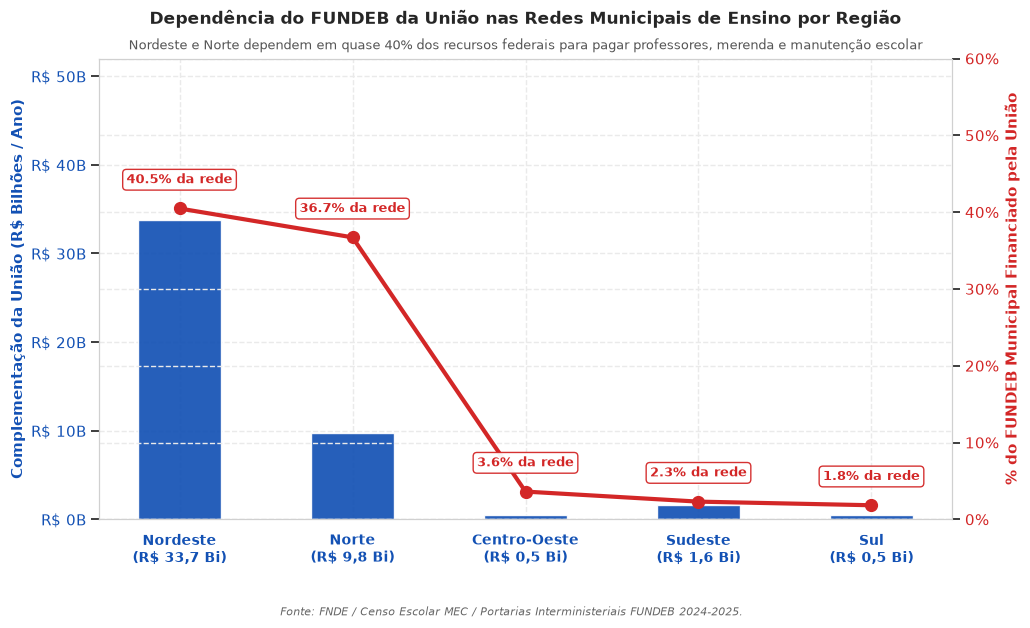

In [14]:
fundeb_reg = df.groupby('regiao').agg({
    'vl_fundeb_rede_municipal': 'sum',
    'vl_fundeb_uniao_rede_municipal': 'sum'
}).reset_index()
fundeb_reg['pct_uniao'] = (fundeb_reg['vl_fundeb_uniao_rede_municipal'] / fundeb_reg['vl_fundeb_rede_municipal']) * 100
fundeb_reg['uniao_bi'] = fundeb_reg['vl_fundeb_uniao_rede_municipal'] / 1e9

# Maior dependência sempre à esquerda
fundeb_reg = fundeb_reg.sort_values('pct_uniao', ascending=False).reset_index(drop=True)

fig, ax1 = plt.subplots(figsize=(11, 6.4))
x = np.arange(len(fundeb_reg))

bars = ax1.bar(x, fundeb_reg['uniao_bi'], color=AZUL_GOV, width=0.48, alpha=0.92, label='Complementação da União (R$ Bi)')
ax1.set_ylabel('Complementação da União (R$ Bilhões / Ano)', color=AZUL_GOV, fontsize=10.5, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=AZUL_GOV)
ax1.yaxis.set_major_formatter(ticker.FormatStrFormatter('R$ %.0fB'))
ax1.set_ylim(0, 52)

# Eixo X com o nome da região E o valor absoluto em R$ Bi (garante 100% de clareza sem colidir com a linha)
labels_x = [f"{r}\n(R$ {v:.1f} Bi)".replace('.', ',') for r, v in zip(fundeb_reg['regiao'], fundeb_reg['uniao_bi'])]
ax1.set_xticks(x)
ax1.set_xticklabels(labels_x, fontsize=10, fontweight='bold', color=AZUL_GOV)


ax2 = ax1.twinx()
line = ax2.plot(x, fundeb_reg['pct_uniao'], color=VERMELHO_GOV, marker='o', linewidth=3.0, markersize=8.5, label='% Financiado pela União')
ax2.set_ylabel('% do FUNDEB Municipal Financiado pela União', color=VERMELHO_GOV, fontsize=10.5, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=VERMELHO_GOV)
ax2.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.0f%%'))
ax2.set_ylim(0, 60)

# Rótulos da linha vermelha com caixa destacada e respiro livre
for i, txt in enumerate(fundeb_reg['pct_uniao']):
    ax2.annotate(f'{txt:.1f}% da rede', 
                 xy=(i, txt), xytext=(0, 16), textcoords='offset points',
                 ha='center', va='bottom', fontsize=9.2, fontweight='bold', color=VERMELHO_GOV,
                 bbox=dict(boxstyle='round,pad=0.3', facecolor='#FFFFFF', edgecolor=VERMELHO_GOV, alpha=0.95))

ax1.set_title('Dependência do FUNDEB da União nas Redes Municipais de Ensino por Região', fontsize=12.5, fontweight='bold', pad=25)
ax1.text(0.5, 1.02, 'Nordeste e Norte dependem em quase 40% dos recursos federais para pagar professores, merenda e manutenção escolar', 
        transform=ax1.transAxes, ha='center', fontsize=9.2, color='#555555')

fig.text(0.5, 0.01, 'Fonte: FNDE / Censo Escolar MEC / Portarias Interministeriais FUNDEB 2024-2025.', 
         ha='center', fontsize=8, style='italic', color='#666666')
plt.subplots_adjust(top=0.88, bottom=0.16)
plt.savefig(os.path.join(OUTPUT_DIR, 'grafico_3_fundeb_uniao_regioes.png'), dpi=300)
plt.show()


## 4. Proteção Escolar: Alcance e Injeção de Recursos do Pé-de-Meia por Região
O programa atende mais de **1,6 milhão de estudantes no Nordeste (15,2% da rede pública)** e **1,2 milhão no Sudeste (8,9%)**, garantindo poupança direta aos jovens contra a evasão escolar.
*Cor sólida Verde Brasil oficial (sem degradê) com margem superior ampliada para enquadramento perfeito dos rótulos.*


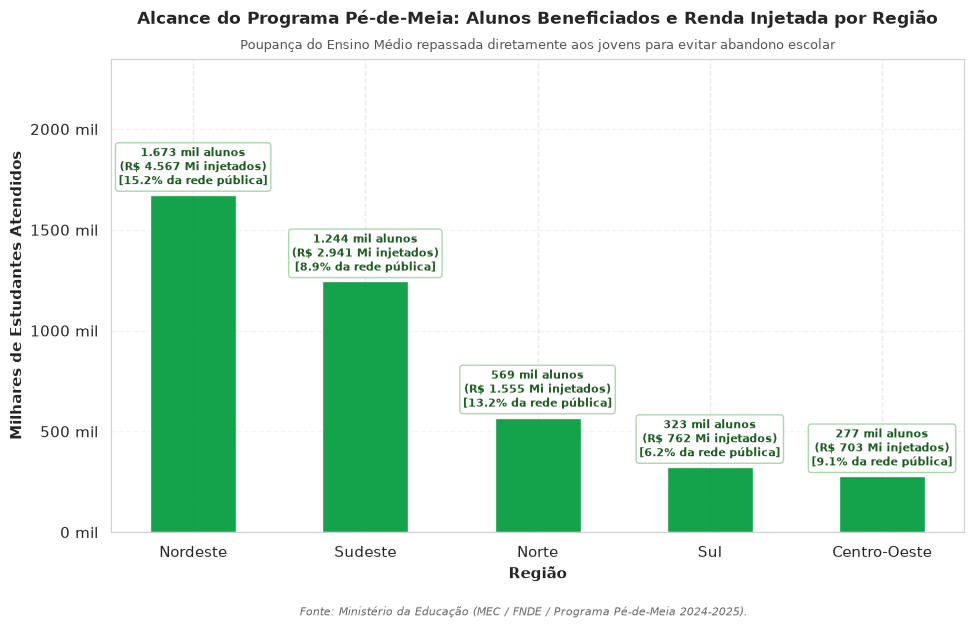

In [15]:
pdm_reg = df.groupby('regiao').agg({
    'qtd_beneficiarios_pe_de_meia': 'sum',
    'vl_pago_pe_de_meia': 'sum',
    'qtd_alunos_rede_publica': 'sum'
}).reset_index()
pdm_reg['benef_milhares'] = pdm_reg['qtd_beneficiarios_pe_de_meia'] / 1000.0
pdm_reg['valor_mi'] = pdm_reg['vl_pago_pe_de_meia'] / 1e6
pdm_reg['pct_rede'] = (pdm_reg['qtd_beneficiarios_pe_de_meia'] / pdm_reg['qtd_alunos_rede_publica']) * 100

# O maior número sempre à esquerda
pdm_reg = pdm_reg.sort_values('benef_milhares', ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(11, 6.4))

# Barra em Verde Brasil sólido
bars = ax.bar(pdm_reg['regiao'], pdm_reg['benef_milhares'], width=0.50, color=VERDE_GOV, alpha=0.92)

ax.set_title('Alcance do Programa Pé-de-Meia: Alunos Beneficiados e Renda Injetada por Região', fontsize=12.5, fontweight='bold', pad=25)
ax.text(0.5, 1.02, 'Poupança do Ensino Médio repassada diretamente aos jovens para evitar abandono escolar', 
        transform=ax.transAxes, ha='center', fontsize=9.2, color='#555555')

for bar, v_mi, pct in zip(bars, pdm_reg['valor_mi'], pdm_reg['pct_rede']):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 35, 
            f"{h:,.0f} mil alunos\n(R$ {v_mi:,.0f} Mi injetados)\n[{pct:.1f}% da rede pública]".replace(',', '.'), 
            ha='center', va='bottom', fontsize=8.2, fontweight='bold', color='#1B5E20',
            bbox=dict(boxstyle='round,pad=0.28', facecolor='#FFFFFF', edgecolor='#A5D6A7', alpha=0.95))

ax.set_ylabel('Milhares de Estudantes Atendidos', fontsize=10.5, fontweight='bold')
ax.set_xlabel('Região', fontsize=10.5, fontweight='bold')
ax.set_ylim(0, 2350)  # Margem generosa no topo: rótulo 100% contido dentro da moldura
ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.0f mil'))
ax.grid(axis='y', alpha=0.5)

fig.text(0.5, 0.01, 'Fonte: Ministério da Educação (MEC / FNDE / Programa Pé-de-Meia 2024-2025).', 
         ha='center', fontsize=8, style='italic', color='#666666')
plt.subplots_adjust(top=0.88, bottom=0.14)
plt.savefig(os.path.join(OUTPUT_DIR, 'grafico_4_pe_de_meia_regioes.png'), dpi=300)
plt.show()


## 5. Saúde Pública: Alívio no Bolso Familiar com a Farmácia Popular
Remédios 100% gratuitos para Hipertensão, Diabetes e Asma aliviam anualmente **R$ 7,7 bilhões** do orçamento familiar no Brasil.
*Identidade visual: Barras em Vermelho Oficial e Linha em Verde Brasil. Economia anual e mensal calculada por paciente atendido (~R$ 50/mês por usuário de remédios contínuos).*


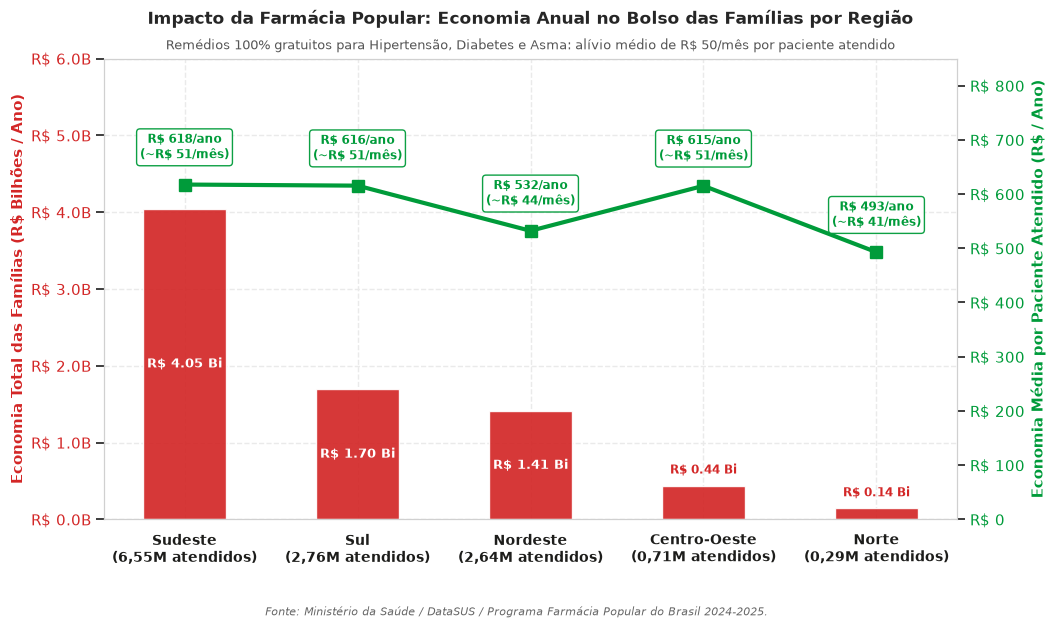

In [21]:
fp_reg = df.groupby('regiao').agg({
    'fp_total': 'sum',
    'bolso_anual_mediano_rs': 'sum',
    'populacao_2025': 'sum'
}).reset_index()

fp_reg['benef_milhoes'] = fp_reg['fp_total'] / 1e6
fp_reg['economia_bi'] = fp_reg['bolso_anual_mediano_rs'] / 1e9
# Cálculo da Economia Média por PACIENTE ATENDIDO (usuários de remédios contínuos)
fp_reg['economia_por_paciente'] = fp_reg['bolso_anual_mediano_rs'] / fp_reg['fp_total']
fp_reg['economia_mes_paciente'] = fp_reg['economia_por_paciente'] / 12.0

# O maior número sempre à esquerda
fp_reg = fp_reg.sort_values('economia_bi', ascending=False).reset_index(drop=True)

fig, ax1 = plt.subplots(figsize=(11, 6.4))
x = np.arange(len(fp_reg))

# Barras em Vermelho Oficial sólido
bars = ax1.bar(x, fp_reg['economia_bi'], width=0.48, color=VERMELHO_GOV, alpha=0.92, label='Economia Total das Famílias (R$ Bi)')
ax1.set_ylabel('Economia Total das Famílias (R$ Bilhões / Ano)', color=VERMELHO_GOV, fontsize=10.5, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=VERMELHO_GOV)
ax1.yaxis.set_major_formatter(ticker.FormatStrFormatter('R$ %.1fB'))
ax1.set_ylim(0, 6.0)

# Eixo X com Nome da Região e Total de Pacientes Atendidos
labels_x = [f"{r}\n({p:.2f}M atendidos)".replace('.', ',') for r, p in zip(fp_reg['regiao'], fp_reg['benef_milhoes'])]
ax1.set_xticks(x)
ax1.set_xticklabels(labels_x, fontsize=9.8, fontweight='bold', color='#1D1D1B')

# Rótulo das barras: dentro da barra para regiões com grande volume
for bar in bars:
    h = bar.get_height()
    if h >= 1.0:
        ax1.text(bar.get_x() + bar.get_width()/2, h / 2, f'R$ {h:.2f} Bi', 
                 ha='center', va='center', fontsize=9.2, fontweight='bold', color='#FFFFFF')
    else:
        ax1.text(bar.get_x() + bar.get_width()/2, h + 0.12, f'R$ {h:.2f} Bi', 
                 ha='center', va='bottom', fontsize=8.5, fontweight='bold', color=VERMELHO_GOV)

ax2 = ax1.twinx()
# Linha em Verde Brasil sólido
line = ax2.plot(x, fp_reg['economia_por_paciente'], color=VERDE_GOV, marker='s', linewidth=3.0, markersize=8.5, label='Economia por Paciente Atendido (R$/ano)')
ax2.set_ylabel('Economia Média por Paciente Atendido (R$ / Ano)', color=VERDE_GOV, fontsize=10.5, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=VERDE_GOV)
ax2.yaxis.set_major_formatter(ticker.FormatStrFormatter('R$ %.0f'))
ax2.set_ylim(0, 850)

for i, (ano, mes) in enumerate(zip(fp_reg['economia_por_paciente'], fp_reg['economia_mes_paciente'])):
    ax2.annotate(f'R$ {ano:.0f}/ano\n(~R$ {mes:.0f}/mês)', 
                 xy=(i, ano), xytext=(0, 16), textcoords='offset points',
                 ha='center', va='bottom', fontsize=8.8, fontweight='bold', color=VERDE_GOV,
                 bbox=dict(boxstyle='round,pad=0.28', facecolor='#FFFFFF', edgecolor=VERDE_GOV, alpha=0.95))

ax1.set_title('Impacto da Farmácia Popular: Economia Anual no Bolso das Famílias por Região', fontsize=12.5, fontweight='bold', pad=25)
ax1.text(0.5, 1.02, 'Remédios 100% gratuitos para Hipertensão, Diabetes e Asma: alívio médio de R$ 50/mês por paciente atendido', 
        transform=ax1.transAxes, ha='center', fontsize=9.2, color='#555555')

fig.text(0.5, 0.01, 'Fonte: Ministério da Saúde / DataSUS / Programa Farmácia Popular do Brasil 2024-2025.', 
         ha='center', fontsize=8, style='italic', color='#666666')
plt.subplots_adjust(top=0.88, bottom=0.16)
plt.grid(False)
plt.savefig(os.path.join(OUTPUT_DIR, 'grafico_5_farmacia_popular_economia_bolso.png'), dpi=300)
plt.show()


## 6. Risco da Desvinculação do Salário Mínimo: Perda Média Anual por Morador
Se o reajuste das aposentadorias fosse desvinculado do Salário Mínimo, os estados do Sul e Sudeste sofreriam a maior perda per capita (**RS perderia R$ 458/ano por habitante e SC R$ 368/ano**).
*O maior número está no topo (RS). Cor sólida Vermelho Oficial (sem degradê) e comentário explicativo posicionado abaixo do gráfico.*


<>:34: SyntaxWarning: invalid escape sequence '\$'
<>:36: SyntaxWarning: invalid escape sequence '\$'
<>:34: SyntaxWarning: invalid escape sequence '\$'
<>:36: SyntaxWarning: invalid escape sequence '\$'
/tmp/ipykernel_98851/822028733.py:34: SyntaxWarning: invalid escape sequence '\$'
  "• E se calcularmos direto POR APOSENTADO? A perda média real no bolso de cada idoso seria de R\$ 2.510,84 ao ano (quase 1,7 salário mínimo a menos!).\n"
/tmp/ipykernel_98851/822028733.py:36: SyntaxWarning: invalid escape sequence '\$'
  "  beneficiária do INSS, quase 1 em cada 4 pessoas). Com isso, a perda média por morador da cidade é a maior do Brasil (R\$ 458,23/morador/ano)."


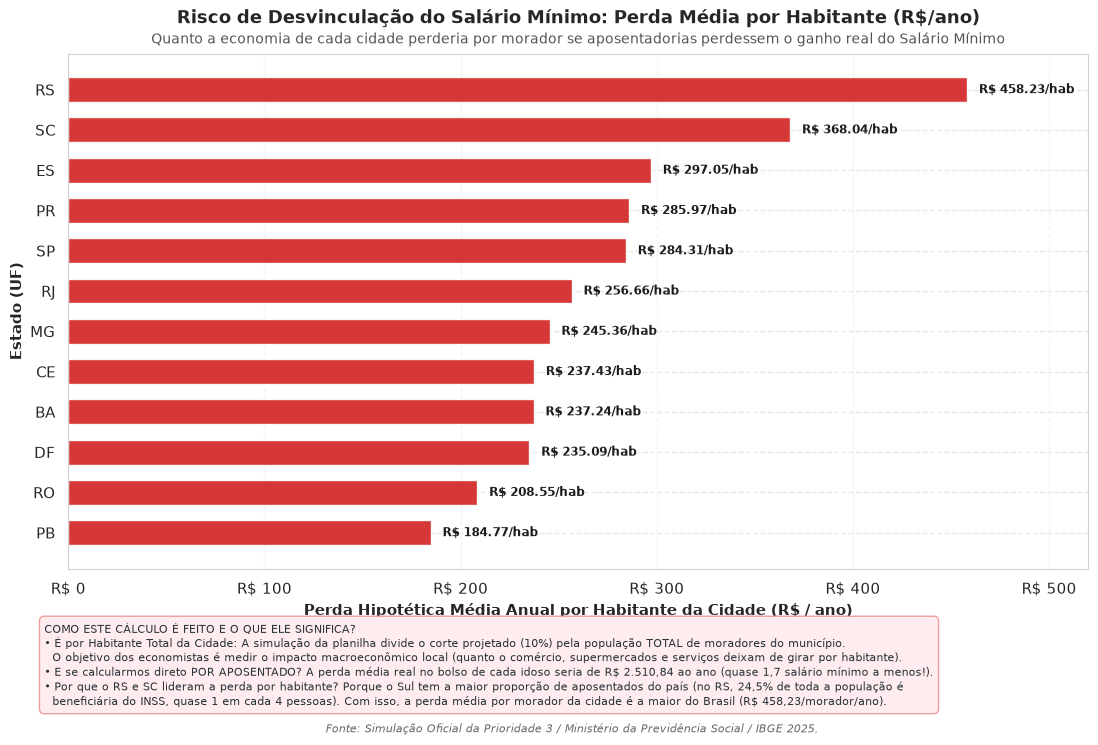

In [17]:
perda_uf = df.groupby('uf')['perda_hipotetica_por_habitante_brl'].mean().reset_index()

# Ordenar do MAIOR para o MENOR (o maior ficará no topo do gráfico)
perda_uf = perda_uf.sort_values('perda_hipotetica_por_habitante_brl', ascending=False).head(12).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(12, 7.8))

# Barra em Vermelho Institucional sólido
bars = ax.barh(perda_uf['uf'], perda_uf['perda_hipotetica_por_habitante_brl'], color=VERMELHO_GOV, height=0.62, alpha=0.92)

# O maior número sempre em cima
ax.invert_yaxis()

ax.set_title('Risco de Desvinculação do Salário Mínimo: Perda Média por Habitante (R$/ano)', fontsize=13, fontweight='bold', pad=22)
ax.text(0.5, 1.02, 'Quanto a economia de cada cidade perderia por morador se aposentadorias perdessem o ganho real do Salário Mínimo', 
        transform=ax.transAxes, ha='center', fontsize=9.8, color='#555555')

for bar in bars:
    w = bar.get_width()
    ax.text(w + 6, bar.get_y() + bar.get_height()/2, f"R$ {w:.2f}/hab", 
            ha='left', va='center', fontsize=8.8, fontweight='bold', color='#1D1D1B')

ax.set_xlim(0, 520)
ax.xaxis.set_major_formatter(ticker.FormatStrFormatter('R$ %.0f'))
ax.set_xlabel('Perda Hipotética Média Anual por Habitante da Cidade (R$ / ano)', fontsize=10.5, fontweight='bold')
ax.set_ylabel('Estado (UF)', fontsize=10.5, fontweight='bold')
ax.grid(axis='x', alpha=0.5)

# Comentário explicativo posicionado ABAIXO do gráfico esclarecendo o cálculo
comentario_perda = (
    "COMO ESTE CÁLCULO É FEITO E O QUE ELE SIGNIFICA?\n"
    "• É por Habitante Total da Cidade: A simulação da planilha divide o corte projetado (10%) pela população TOTAL de moradores do município.\n"
    "  O objetivo dos economistas é medir o impacto macroeconômico local (quanto o comércio, supermercados e serviços deixam de girar por habitante).\n"
    "• E se calcularmos direto POR APOSENTADO? A perda média real no bolso de cada idoso seria de R\$ 2.510,84 ao ano (quase 1,7 salário mínimo a menos!).\n"
    "• Por que o RS e SC lideram a perda por habitante? Porque o Sul tem a maior proporção de aposentados do país (no RS, 24,5% de toda a população é\n"
    "  beneficiária do INSS, quase 1 em cada 4 pessoas). Com isso, a perda média por morador da cidade é a maior do Brasil (R\$ 458,23/morador/ano)."
)
fig.text(0.06, 0.045, comentario_perda, fontsize=7.8, color='#263238', linespacing=1.35,
         bbox=dict(boxstyle='round,pad=0.45', facecolor='#FFEBEE', edgecolor='#EF9A9A', alpha=0.95))

fig.text(0.5, 0.01, 'Fonte: Simulação Oficial da Prioridade 3 / Ministério da Previdência Social / IBGE 2025.', 
         ha='center', fontsize=8, style='italic', color='#666666')

plt.subplots_adjust(left=0.08, right=0.93, top=0.88, bottom=0.22)
plt.savefig(os.path.join(OUTPUT_DIR, 'grafico_6_perda_desvinculacao_salario_minimo.png'), dpi=300)
plt.show()


## 7. Risco da Desvinculação do Salário Mínimo: Perda Média Anual por Aposentado (R$/ano)
Enquanto o gráfico anterior mede a perda diluída por morador da cidade, este gráfico mede o **impacto financeiro direto e individual no bolso de cada aposentado do INSS**.
*No Brasil, cada idoso aposentado perderia em média **R$ 2.510,84 ao ano** (~R$ 209/mês), o que representa **quase 1,7 salário mínimo anual a menos** na renda familiar.*


<>:45: SyntaxWarning: invalid escape sequence '\$'
<>:47: SyntaxWarning: invalid escape sequence '\$'
<>:45: SyntaxWarning: invalid escape sequence '\$'
<>:47: SyntaxWarning: invalid escape sequence '\$'
/tmp/ipykernel_98851/230688474.py:45: SyntaxWarning: invalid escape sequence '\$'
  "• Mais de 1,6 Salário Mínimo a Menos: No Brasil, cada aposentado perderia em média R\$ 2.510,84 ao ano (~R\$ 209/mês), valor que faz falta direta na comida e remédios.\n"
/tmp/ipykernel_98851/230688474.py:47: SyntaxWarning: invalid escape sequence '\$'
  "  maiores que o piso nacional, fazendo com que o corte de 10% represente perdas nominais superiores a R\$ 3.000,00 anuais por idoso aposentado."


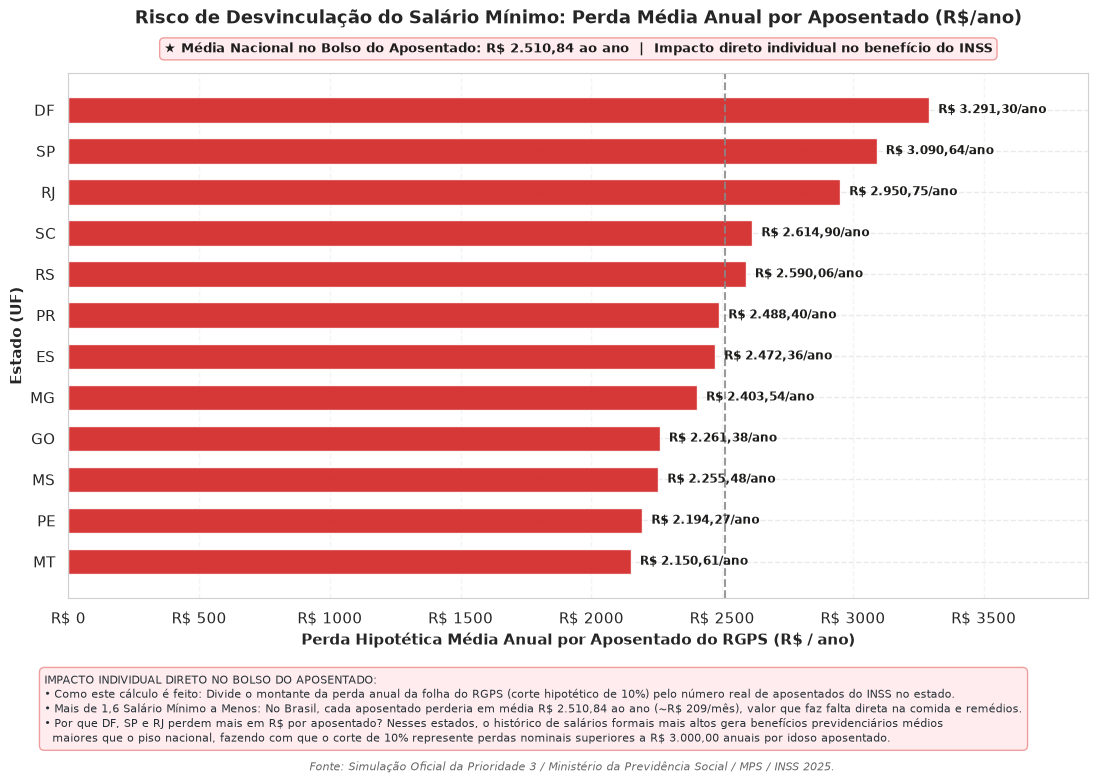

In [18]:
uf_apos = df.groupby('uf').agg({
    'perda_hipotetica_anual_brl': 'sum',
    'aposentadorias_rgps_dezembro': 'sum'
}).reset_index()
uf_apos['perda_por_aposentado'] = uf_apos['perda_hipotetica_anual_brl'] / uf_apos['aposentadorias_rgps_dezembro']

# Top 12 ordenado do MAIOR para o MENOR (maior no topo do gráfico)
perda_apos = uf_apos.sort_values('perda_por_aposentado', ascending=False).head(12).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(12, 8.2))

# Barra em Vermelho Institucional sólido
bars = ax.barh(perda_apos['uf'], perda_apos['perda_por_aposentado'], color=VERMELHO_GOV, height=0.62, alpha=0.92)

# O maior número sempre em cima
ax.invert_yaxis()

ax.set_title('Risco de Desvinculação do Salário Mínimo: Perda Média Anual por Aposentado (R$/ano)', fontsize=13, fontweight='bold', pad=36)

# Média Nacional ponderada no bolso do aposentado posicionada ACIMA do gráfico
media_br_apos = df['perda_hipotetica_anual_brl'].sum() / df['aposentadorias_rgps_dezembro'].sum()
header_text = f'★ Média Nacional no Bolso do Aposentado: R$ {media_br_apos:,.2f} ao ano  |  Impacto direto individual no benefício do INSS'.replace(',', 'X').replace('.', ',').replace('X', '.')
ax.text(0.5, 1.04, header_text, transform=ax.transAxes, ha='center', fontsize=9.2, fontweight='bold',
        color='#1D1D1B', bbox=dict(boxstyle='round,pad=0.35', facecolor='#FFEBEE', edgecolor='#EF9A9A', alpha=0.95))

for bar in bars:
    w = bar.get_width()
    txt = f"R$ {w:,.2f}/ano".replace(',', 'X').replace('.', ',').replace('X', '.')
    ax.text(w + 35, bar.get_y() + bar.get_height()/2, txt, 
            ha='left', va='center', fontsize=8.8, fontweight='bold', color='#1D1D1B')

ax.set_xlim(0, 3900)
ax.xaxis.set_major_formatter(ticker.FormatStrFormatter('R$ %.0f'))
ax.set_xlabel('Perda Hipotética Média Anual por Aposentado do RGPS (R$ / ano)', fontsize=10.5, fontweight='bold')
ax.set_ylabel('Estado (UF)', fontsize=10.5, fontweight='bold')
ax.grid(axis='x', alpha=0.5)

# Linha da média nacional tracejada
ax.axvline(media_br_apos, color='#888888', linestyle='--', linewidth=1.5, alpha=0.85)

# Comentário explicativo posicionado ABAIXO do gráfico
comentario_apos = (
    "IMPACTO INDIVIDUAL DIRETO NO BOLSO DO APOSENTADO:\n"
    "• Como este cálculo é feito: Divide o montante da perda anual da folha do RGPS (corte hipotético de 10%) pelo número real de aposentados do INSS no estado.\n"
    "• Mais de 1,6 Salário Mínimo a Menos: No Brasil, cada aposentado perderia em média R\$ 2.510,84 ao ano (~R\$ 209/mês), valor que faz falta direta na comida e remédios.\n"
    "• Por que DF, SP e RJ perdem mais em R$ por aposentado? Nesses estados, o histórico de salários formais mais altos gera benefícios previdenciários médios\n"
    "  maiores que o piso nacional, fazendo com que o corte de 10% represente perdas nominais superiores a R\$ 3.000,00 anuais por idoso aposentado."
)
fig.text(0.06, 0.045, comentario_apos, fontsize=7.8, color='#263238', linespacing=1.35,
         bbox=dict(boxstyle='round,pad=0.45', facecolor='#FFEBEE', edgecolor='#EF9A9A', alpha=0.95))

fig.text(0.5, 0.01, 'Fonte: Simulação Oficial da Prioridade 3 / Ministério da Previdência Social / MPS / INSS 2025.', 
         ha='center', fontsize=8, style='italic', color='#666666')

plt.subplots_adjust(left=0.08, right=0.93, top=0.86, bottom=0.22)
plt.savefig(os.path.join(OUTPUT_DIR, 'grafico_7_perda_desvinculacao_por_aposentado.png'), dpi=300)
plt.show()


## 📋 8. Tabela Resumo Consolidada por Região
Síntese executiva comparando População, Injeção da Seguridade Social, Dependência do FUNDEB e Economia da Farmácia Popular por grande região do Brasil.


In [19]:
tab_reg = df.groupby('regiao').agg({
    'populacao_2025': 'sum',
    'renda_social_prev_total': 'sum',
    'pib_municipal_precos_correntes_brl': 'sum',
    'vl_fundeb_uniao_rede_municipal': 'sum',
    'vl_pago_pe_de_meia': 'sum',
    'bolso_anual_mediano_rs': 'sum'
}).reset_index()

tab_reg['% Seguridade/PIB'] = (tab_reg['renda_social_prev_total'] / tab_reg['pib_municipal_precos_correntes_brl']) * 100
tab_reg['População (Milhões)'] = tab_reg['populacao_2025'] / 1e6
tab_reg['Renda Seguridade (R$ Bi)'] = tab_reg['renda_social_prev_total'] / 1e9
tab_reg['FUNDEB União (R$ Bi)'] = tab_reg['vl_fundeb_uniao_rede_municipal'] / 1e9
tab_reg['Pé-de-Meia (R$ Mi)'] = tab_reg['vl_pago_pe_de_meia'] / 1e6
tab_reg['Econ. Farmácia Popular (R$ Bi)'] = tab_reg['bolso_anual_mediano_rs'] / 1e9

colunas_apresentacao = ['regiao', 'População (Milhões)', '% Seguridade/PIB', 
                        'Renda Seguridade (R$ Bi)', 'FUNDEB União (R$ Bi)', 
                        'Pé-de-Meia (R$ Mi)', 'Econ. Farmácia Popular (R$ Bi)']

df_apresentacao = tab_reg[colunas_apresentacao].rename(columns={'regiao': 'Região'})
display(df_apresentacao.style.format({
    'População (Milhões)': '{:.2f}M',
    '% Seguridade/PIB': '{:.1f}%',
    'Renda Seguridade (R$ Bi)': 'R$ {:.2f}B',
    'FUNDEB União (R$ Bi)': 'R$ {:.2f}B',
    'Pé-de-Meia (R$ Mi)': 'R$ {:.1f}M',
    'Econ. Farmácia Popular (R$ Bi)': 'R$ {:.2f}B'
}))


,Região,População (Milhões),% Seguridade/PIB,Renda Seguridade (R$ Bi),FUNDEB União (R$ Bi),Pé-de-Meia (R$ Mi),Econ. Farmácia Popular (R$ Bi)
0,Centro-Oeste,17.24M,5.4%,R$ 62.52B,R$ 0.50B,R$ 702.7M,R$ 0.44B
1,Nordeste,57.24M,17.9%,R$ 271.25B,R$ 33.73B,R$ 4567.0M,R$ 1.41B
2,Norte,18.80M,9.5%,R$ 60.32B,R$ 9.76B,R$ 1554.6M,R$ 0.14B
3,Sudeste,88.83M,8.9%,R$ 516.44B,R$ 1.58B,R$ 2940.8M,R$ 4.05B
4,Sul,31.31M,10.2%,R$ 187.37B,R$ 0.50B,R$ 762.4M,R$ 1.70B
